# 06 – Portfolio stress testing

How would the portfolio's PD change under adverse economic scenarios?
Borrower characteristics in the test portfolio (30,000 borrowers) are shocked, and PDs are recomputed with the final model (XGBoost with monotonic constraints).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier

train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")

target = "SeriousDlqin2yrs"
X_train, y_train = train.drop(columns=target), train[target]
X_test, y_test = test.drop(columns=target), test[target]

mora = ["NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTime60-89DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate"]

def agregar_variables(df):
    """Adds engineered features to a copy of the dataset."""
    df = df.copy()
    df["total_past_due"] = df[mora].sum(axis=1)
    df["ever_late"] = (df["total_past_due"] > 0).astype(int)
    df["monthly_debt"] = df["DebtRatio"] * df["MonthlyIncome"]
    df["income_per_person"] = df["MonthlyIncome"] / (df["NumberOfDependents"] + 1)
    df["non_real_estate_lines"] = (df["NumberOfOpenCreditLinesAndLoans"]
                                   - df["NumberRealEstateLoansOrLines"]).clip(lower=0)
    return df

direcciones = {
    "NumberOfTime30-59DaysPastDueNotWorse": 1, "NumberOfTime60-89DaysPastDueNotWorse": 1,
    "NumberOfTimes90DaysLate": 1, "total_past_due": 1, "ever_late": 1,
    "DebtRatio": 1, "special_code": 1,
    "age": -1, "MonthlyIncome": -1, "income_per_person": -1,
}

X_train_fe = agregar_variables(X_train)
restricciones = tuple(direcciones.get(col, 0) for col in X_train_fe.columns)

modelo = XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=4,
    subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
    random_state=42, n_jobs=-1, monotone_constraints=restricciones,
)
modelo.fit(X_train_fe, y_train)

pd_base = modelo.predict_proba(agregar_variables(X_test))[:, 1]
print(f"Base scenario – average PD: {pd_base.mean():.2%} | observed: {y_test.mean():.2%}")

Base scenario – average PD: 6.71% | observed: 6.68%


## 1. Scenarios
Hypothetical scenarios translated into borrower-level shocks (assumptions, not estimates).

In [2]:
escenarios = {
    #            utilización  ingreso  deuda   nuevos atrasos 30-59  nuevos atrasos 90+
    "Base":     {"util": 0.00, "ingreso": 0.00, "deuda": 0.00, "atraso_30": 0.00, "atraso_90": 0.00},
    "Moderate": {"util": 0.10, "ingreso": -0.05, "deuda": 0.10, "atraso_30": 0.05, "atraso_90": 0.00},
    "Adverse":  {"util": 0.25, "ingreso": -0.15, "deuda": 0.20, "atraso_30": 0.10, "atraso_90": 0.02},
    "Severe":   {"util": 0.50, "ingreso": -0.30, "deuda": 0.40, "atraso_30": 0.20, "atraso_90": 0.05},
}
pd.DataFrame(escenarios).T

,util,ingreso,deuda,atraso_30,atraso_90
Base,0.00,0.00,0.0,0.00,0.00
Moderate,0.10,-0.05,0.1,0.05,0.00
Adverse,0.25,-0.15,0.2,0.10,0.02
Severe,0.50,-0.30,0.4,0.20,0.05


## 2. Apply the scenarios

In [3]:
def aplicar_shock(X, shock, seed=42):
    """Applies a stress scenario to a copy of the borrower data."""
    X = X.copy()
    rng = np.random.default_rng(seed)

    # 1. Más uso de las tarjetas
    X["RevolvingUtilizationOfUnsecuredLines"] *= (1 + shock["util"])

    # 2. Cae el ingreso
    X["MonthlyIncome"] *= (1 + shock["ingreso"])

    # 3. DebtRatio = deuda / ingreso: sube la deuda y baja el ingreso
    X["DebtRatio"] *= (1 + shock["deuda"]) / (1 + shock["ingreso"])

    # 4. Nuevos atrasos para una parte de los clientes, al azar
    n = len(X)
    nuevos_30 = rng.random(n) < shock["atraso_30"]
    nuevos_90 = rng.random(n) < shock["atraso_90"]
    X.loc[nuevos_30, "NumberOfTime30-59DaysPastDueNotWorse"] += 1
    X.loc[nuevos_90, "NumberOfTimes90DaysLate"] += 1

    return X

In [4]:
pds_esc = {}
resumen = []

for nombre, shock in escenarios.items():
    X_shock = agregar_variables(aplicar_shock(X_test, shock))
    pds_esc[nombre] = modelo.predict_proba(X_shock)[:, 1]
    resumen.append({
        "Scenario": nombre,
        "Average PD": pds_esc[nombre].mean(),
        "Expected defaults": pds_esc[nombre].sum(),
        "% borrowers with PD > 20%": (pds_esc[nombre] > 0.20).mean(),
    })

resumen = pd.DataFrame(resumen).set_index("Scenario")
resumen["Change vs. base"] = resumen["Average PD"] / resumen.loc["Base", "Average PD"] - 1
resumen.style.format({"Average PD": "{:.2%}", "Expected defaults": "{:,.0f}",
                      "% borrowers with PD > 20%": "{:.2%}", "Change vs. base": "{:+.1%}"})

,Average PD,Expected defaults,% borrowers with PD > 20%,Change vs. base
Scenario,,,,
Base,6.71%,"2,013",8.67%,+0.0%
Moderate,8.13%,"2,440",10.88%,+21.3%
Adverse,9.61%,"2,884",13.34%,+43.3%
Severe,12.21%,"3,664",18.59%,+82.1%


## 3. Sensitivity analysis: one factor at a time (adverse scenario)

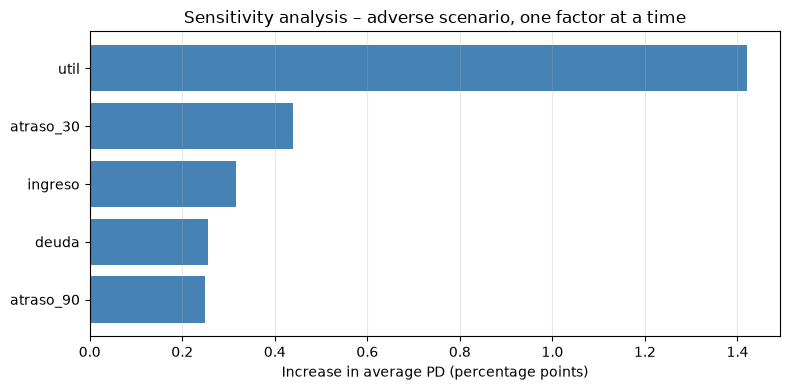

,Factor,Impact on average PD (pp)
4,atraso_90,0.25
2,deuda,0.26
1,ingreso,0.32
3,atraso_30,0.44
0,util,1.42


In [5]:
adverso = escenarios["Adverse"]
sin_shock = escenarios["Base"]
pd_base_media = pds_esc["Base"].mean()

sensibilidad = []
for factor in adverso:
    shock_solo = dict(sin_shock)          # todo en cero...
    shock_solo[factor] = adverso[factor]  # ...menos este factor
    X_shock = agregar_variables(aplicar_shock(X_test, shock_solo))
    pd_media = modelo.predict_proba(X_shock)[:, 1].mean()
    sensibilidad.append({"Factor": factor,
                         "Impact on average PD (pp)": (pd_media - pd_base_media) * 100})

sens = pd.DataFrame(sensibilidad).sort_values("Impact on average PD (pp)")

plt.figure(figsize=(8, 4))
plt.barh(sens["Factor"], sens["Impact on average PD (pp)"], color="steelblue")
plt.xlabel("Increase in average PD (percentage points)")
plt.title("Sensitivity analysis – adverse scenario, one factor at a time")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../reports/figures/stress_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()
sens.round(2)

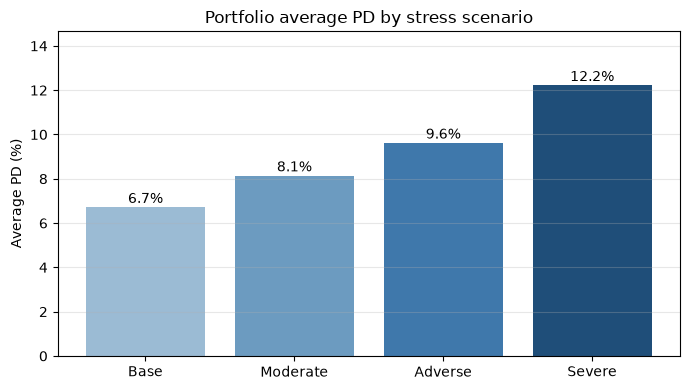

In [6]:
plt.figure(figsize=(7, 4))
barras = plt.bar(resumen.index, resumen["Average PD"] * 100,
                 color=["#9bbbd4", "#6c9bc0", "#3f78ab", "#1f4e79"])
for barra, valor in zip(barras, resumen["Average PD"] * 100):
    plt.text(barra.get_x() + barra.get_width() / 2, valor + 0.2,
             f"{valor:.1f}%", ha="center")
plt.ylabel("Average PD (%)")
plt.title("Portfolio average PD by stress scenario")
plt.ylim(0, resumen["Average PD"].max() * 100 * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("../reports/figures/stress_scenarios.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusions

| Scenario | Average PD | Expected defaults | Borrowers with PD > 20% | Change vs. base |
|---|---|---|---|---|
| Base | 6.71% | 2,013 | 8.67% | – |
| Moderate | 8.13% | 2,440 | 10.88% | +21% |
| Adverse | 9.61% | 2,884 | 13.34% | +43% |
| **Severe** | **12.21%** | **3,664** | **18.59%** | **+82%** |

*Portfolio: 30,000 borrowers (test set). Model: XGBoost with monotonic constraints (notebook 05b).*

- **Under the severe scenario, the portfolio's average PD almost doubles** (6.71% → 12.21%), adding about 1,650 expected defaults, and the share of high-risk borrowers (PD > 20%) more than doubles.
- **The impact grows faster than the shocks:** doubling the shocks from the adverse to the severe scenario nearly doubles the PD increase (+43% → +82%).
- **Revolving utilization drives the stress:** on its own it explains 1.42 pp of the 2.90 pp increase in the adverse scenario, more than all other factors combined. It is the key early-warning indicator to monitor.
- **Delinquency shocks are small for the portfolio but large per borrower:** each new 90+ day delinquency raises that borrower's PD by ~12.5 pp, and each new 30–59 day delinquency by ~4.4 pp.
- **Factors interact:** the sum of the individual impacts (2.69 pp) is lower than the combined adverse scenario (2.90 pp). Combined scenarios are needed to capture compounding effects.

**Limitations:**
- Shocks are hypothetical assumptions applied directly to borrower characteristics, not derived from a macroeconomic model (the dataset has no macro variables).
- The model was trained on a single period and assumes relationships remain stable under stress.
- No second-round effects (e.g., banks cutting credit limits) or exposure data are included: results are expressed in PD and number of expected defaults, not in monetary losses.